In [1]:
import sys
sys.path.append("..")

import joblib
import matplotlib.pyplot as plt
import shap

from src.preprocessing.montagem import carregar_base
from src.preprocessing.features import separar_xy
from src.modeling.pipeline import SEMENTE
from src.evaluation.validacao import dividir_treino_teste
from src.evaluation.interpretabilidade import coeficientes, valores_shap, importancia_agrupada
from src.visualization.graficos import salvar_figura

modelo = joblib.load("../data/processed/modelo_final.joblib")
X, y, w, g = separar_xy(carregar_base())
(Xtr, ytr, wtr, gtr), (Xte, yte, wte, gte) = dividir_treino_teste(X, y, w, g)

X_fundo = Xtr.sample(2_000, random_state=SEMENTE)
X_shap = Xte.sample(20_000, random_state=SEMENTE)
sv = valores_shap(modelo, X_shap, X_fundo)

c:\Users\João Paulo\Desktop\Pessoal\Faculdade\fase-3\tech-challenge-fase3\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


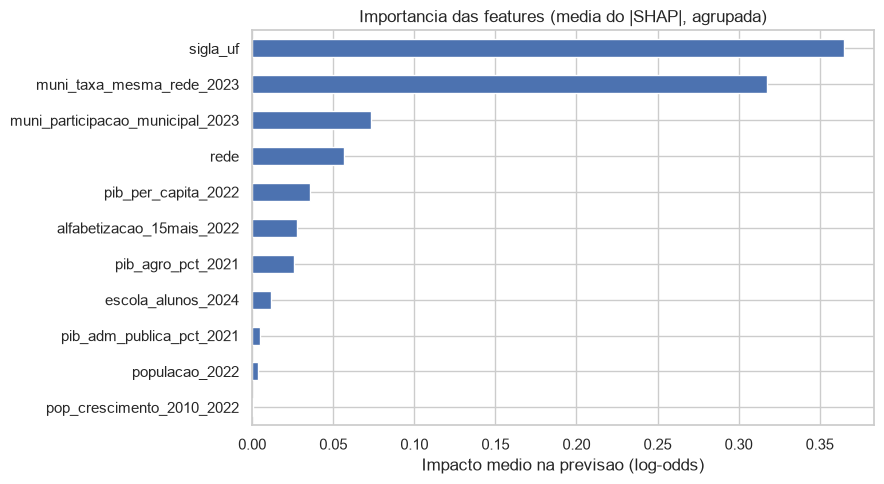

[OK] figura salva em images/interp_01_importancia_agrupada.png
sigla_uf                            0.3652
muni_taxa_mesma_rede_2023           0.3172
muni_participacao_municipal_2023    0.0735
rede                                0.0568
pib_per_capita_2022                 0.0358
alfabetizacao_15mais_2022           0.0275
pib_agro_pct_2021                   0.0260
escola_alunos_2024                  0.0117
pib_adm_publica_pct_2021            0.0051
populacao_2022                      0.0037
pop_crescimento_2010_2022           0.0002


In [2]:
imp = importancia_agrupada(sv)
fig, ax = plt.subplots(figsize=(9, 5))
imp.plot.barh(ax=ax)
ax.set_title("Importancia das features (media do |SHAP|, agrupada)")
ax.set_xlabel("Impacto medio na previsao (log-odds)")
fig.tight_layout()
plt.show()
salvar_figura(fig, "interp_01_importancia_agrupada")
print(imp.sort_values(ascending=False).round(4).to_string())

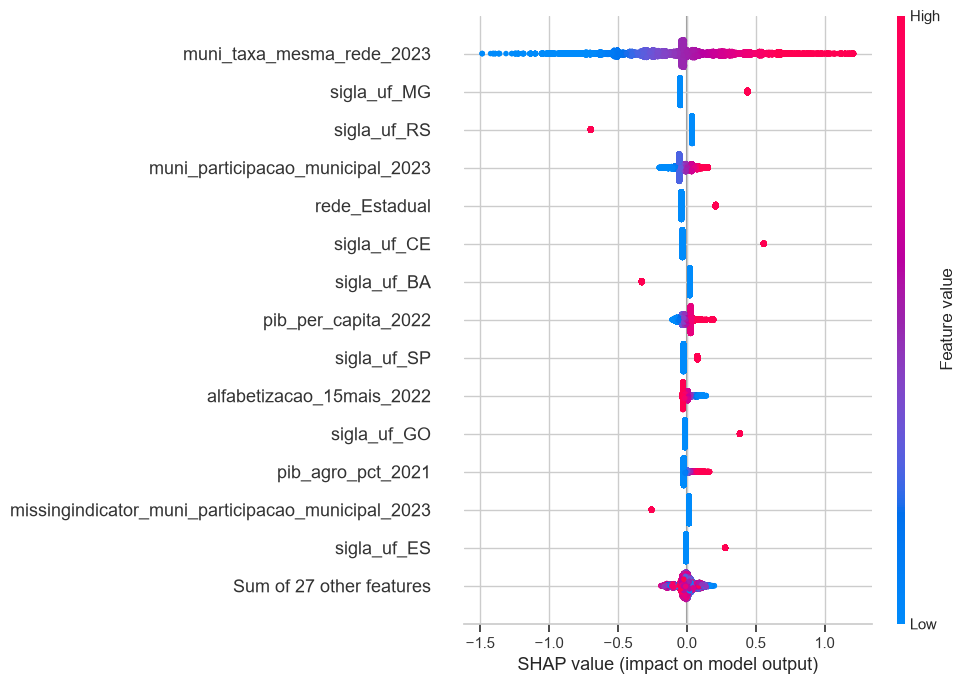

[OK] figura salva em images/interp_02_shap_beeswarm.png
                                          feature   coef
missingindicator_muni_participacao_municipal_2023 -0.061
                        alfabetizacao_15mais_2022 -0.036
                               escola_alunos_2024 -0.015
                                   populacao_2022 -0.005
               missingindicator_pib_agro_pct_2021 -0.000
        missingindicator_pib_adm_publica_pct_2021 -0.000
                        pop_crescimento_2010_2022  0.000
                         pib_adm_publica_pct_2021  0.007
       missingindicator_muni_taxa_mesma_rede_2023  0.011
                                   rede_Municipal  0.032
                                pib_agro_pct_2021  0.034
                              pib_per_capita_2022  0.044
                 muni_participacao_municipal_2023  0.069
                                    rede_Estadual  0.249
                        muni_taxa_mesma_rede_2023  0.439


In [3]:
shap.plots.beeswarm(sv, max_display=15, show=False)
fig = plt.gcf()
fig.set_size_inches(10, 7)
fig.tight_layout()
plt.show()
salvar_figura(fig, "interp_02_shap_beeswarm")

coef = coeficientes(modelo)
print(coef[~coef["feature"].str.startswith("sigla_uf")].round(3).to_string(index=False))

## Conclusoes da interpretabilidade

- **Dois fatores concentram ~75% do impacto (media do |SHAP|):** a UF (0,365) e a taxa de alfabetizacao do municipio em 2023 na mesma rede do aluno (0,317). As 6 features do IBGE somam ~0,10.
- **Historico recente:** municipio 1 desvio-padrao acima da media em 2023 multiplica a chance do aluno estar alfabetizado por ~1,55.
- **Efeito proprio do estado** (descontado o historico de 2023): CE, MG, GO e ES acima; RS (maior efeito negativo) e BA abaixo.
- **Rede estadual** com coeficiente maior que a municipal (0,249 x 0,032).
- **Ausencia de dado municipal em 2023** aumenta o risco: falta de informacao tambem e sinal de alerta.
- **Alfabetizacao adulta com sinal negativo pequeno:** efeito condicional a UF e ao historico, ligado a cidades grandes e correlacionado com o PIB per capita. Nao interpretar como causal.
- **Regularizacao (C=0,01)** zerou o crescimento populacional: selecao automatica de variaveis.

**Conclusao:** o perfil socioeconomico do municipio explica pouco. O que diferencia os resultados e o estado (politica educacional) e o desempenho recente do proprio municipio. Coerente com o teste de Simpson (EDA) e com o AUC dentro das UFs (0,52 a 0,64).